In [1]:
import os
import geopandas as gpd
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold, GroupKFold
from xgboost import XGBClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    classification_report
)
import shap
import matplotlib.pyplot as plt

In [2]:
# ==============================================================================
# 1. LOAD FULL-FEATURE ENRICHED DATASET
# ==============================================================================
full_feat_path = os.path.join("../Datasets", "RZLT_Samples", "RZLT_AllCodes_10to1_FullFeatures.geojson")
if not os.path.exists(full_feat_path):
    full_feat_path = "RZLT_AllCodes_10to1_FullFeatures.geojson"

gdf = gpd.read_file(full_feat_path)

# Policy-Only feature set (using TRUE national density; excluding LOCAL_AUTHORITY)
num_cols = [
    'SITE_AREA', 'LOG_SITE_AREA',
    'SHAPE_COMPACTNESS', 'PERIM_TO_AREA',
    'TRUE_PARCELS_WITHIN_500M', 'TRUE_PARCELS_WITHIN_1000M', 'LOG_TRUE_PARCELS_500M',
    'DIST_TO_BUS_M', 'DIST_TO_RAIL_LUAS_M', 'DIST_TO_ANY_TRANSIT_M',
    'BUS_STOPS_WITHIN_500M', 'LOG_DIST_BUS', 'LOG_DIST_RAIL_LUAS'
]
num_cols = [c for c in num_cols if c in gdf.columns]
cat_cols = ['ZONE_GZT']

gdf['ZONE_GZT'] = gdf['ZONE_GZT'].fillna("Unknown").astype(str).str.strip()
gdf['LOCAL_AUTHORITY'] = gdf['LOCAL_AUTHORITY'].fillna("Unknown").astype(str).str.strip()

X_df = gdf[num_cols + cat_cols].copy()
y = gdf['target'].values
groups = gdf['LOCAL_AUTHORITY'].values

def evaluate_cv(cv_splitter, split_name, use_groups=False):
    oof_probs = np.zeros(len(y))
    fold_metrics = []
    splits = cv_splitter.split(X_df, y, groups) if use_groups else cv_splitter.split(X_df, y)

    for fold, (train_idx, val_idx) in enumerate(splits, start=1):
        X_tr_raw, X_va_raw = X_df.iloc[train_idx], X_df.iloc[val_idx]
        y_tr, y_va = y[train_idx], y[val_idx]

        # Skip fold if a held-out county happens to have 0 exclusions
        if len(np.unique(y_va)) < 2:
            continue

        ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
        tr_cat = ohe.fit_transform(X_tr_raw[cat_cols])
        va_cat = ohe.transform(X_va_raw[cat_cols])

        X_tr = np.hstack([X_tr_raw[num_cols].values, tr_cat])
        X_va = np.hstack([X_va_raw[num_cols].values, va_cat])

        fold_spw = (y_tr == 0).sum() / (y_tr == 1).sum()

        model = XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=5,
            subsample=0.85,
            colsample_bytree=0.85,
            scale_pos_weight=fold_spw,
            eval_metric='aucpr',
            random_state=42 + fold,
            n_jobs=-1
        )
        model.fit(X_tr, y_tr)
        probs = model.predict_proba(X_va)[:, 1]
        oof_probs[val_idx] = probs

        fold_metrics.append({
            'ROC_AUC': roc_auc_score(y_va, probs),
            'PR_AUC_Inclusion(1)': average_precision_score(y_va, probs),
            'PR_AUC_Exclusion(0)': average_precision_score(1 - y_va, 1 - probs)
        })

    res_df = pd.DataFrame(fold_metrics)
    print(f"=== {split_name} (Mean Across {len(res_df)} Folds) ===")
    print(res_df.mean().round(4).to_string())

    # Threshold optimization for Exclusion F1
    prec_0, rec_0, thresholds = precision_recall_curve(1 - y, 1 - oof_probs)
    f1_0 = (2 * prec_0 * rec_0) / np.maximum(prec_0 + rec_0, 1e-8)
    best_idx = np.argmax(f1_0[:-1])
    best_thresh = 1.0 - thresholds[best_idx]
    print(f"Optimal Inclusion Cutoff: {best_thresh:.4f} | Max Exclusion F1: {f1_0[best_idx]:.4f}\n")
    return model, X_va, ohe

In [3]:
# ==============================================================================
# 2. RUN STRATIFIED 5-FOLD CV vs. SPATIAL GROUP K-FOLD (UNSEEN COUNTIES)
# ==============================================================================
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
last_model, last_X_va, last_ohe = evaluate_cv(skf, "Stratified 5-Fold CV (True National Density)", use_groups=False)

gkf = GroupKFold(n_splits=5)
evaluate_cv(gkf, "Spatial GroupKFold CV (Unseen Local Authorities)", use_groups=True)

=== Stratified 5-Fold CV (True National Density) (Mean Across 5 Folds) ===
ROC_AUC                0.9715
PR_AUC_Inclusion(1)    0.9967
PR_AUC_Exclusion(0)    0.8143
Optimal Inclusion Cutoff: 0.2158 | Max Exclusion F1: 0.7787

=== Spatial GroupKFold CV (Unseen Local Authorities) (Mean Across 4 Folds) ===
ROC_AUC                0.8083
PR_AUC_Inclusion(1)    0.9427
PR_AUC_Exclusion(0)    0.5901
Optimal Inclusion Cutoff: 0.9470 | Max Exclusion F1: 0.2501



(XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=0.85, device=None, early_stopping_rounds=None,
               enable_categorical=True, eval_metric='aucpr', feature_types=None,
               feature_weights=None, gamma=None, grow_policy=None,
               importance_type=None, interaction_constraints=None,
               learning_rate=0.05, max_bin=None, max_cat_threshold=None,
               max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
               max_leaves=None, min_child_weight=None, missing=nan,
               monotone_constraints=None, multi_strategy=None, n_estimators=300,
               n_jobs=-1, num_parallel_tree=None, ...),
 array([[0.02389556, 0.45762819, 0.33899238, ..., 0.        , 0.        ,
         0.        ],
        [0.03289649, 0.44625828, 0.29257486, ..., 0.        , 0.        ,
         0.        ],
        [0.5210492 , 0.69776976, 0.0587

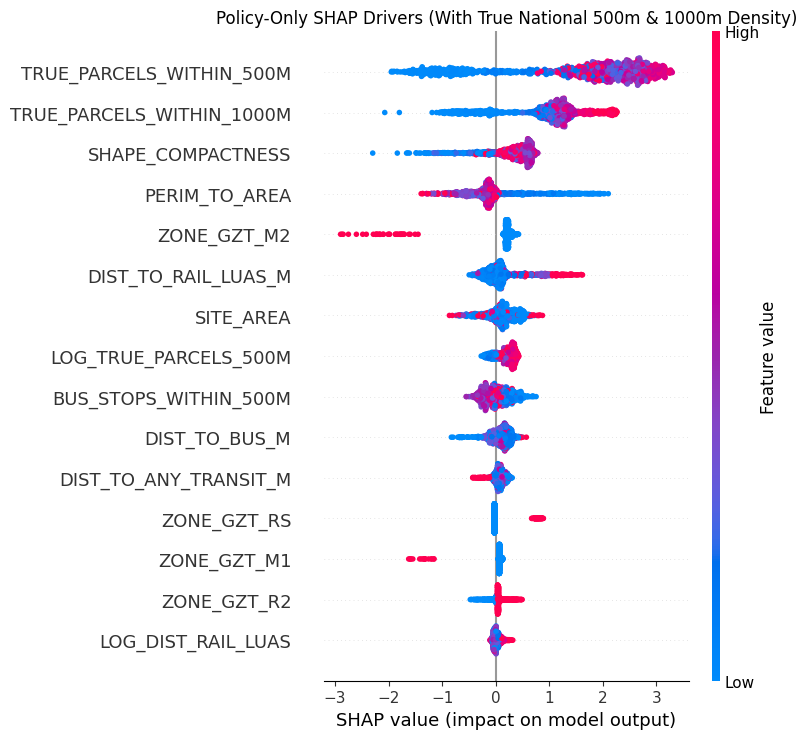

In [4]:
# ==============================================================================
# 3. UPDATED SHAP BEESWARM PLOT
# ==============================================================================
feature_names = num_cols + list(last_ohe.get_feature_names_out(cat_cols))
explainer = shap.TreeExplainer(last_model)
shap_values = explainer(last_X_va)
shap_values.feature_names = feature_names

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, last_X_va, feature_names=feature_names, max_display=15, show=False)
plt.title("Policy-Only SHAP Drivers (With True National 500m & 1000m Density)", fontsize=12)
plt.tight_layout()
plt.show()